# Projet 8 — Les Plus Beaux Logis de Paris
## Analyse historique et valorisation du portefeuille

**Steve Bell · 6 octobre 2026**

Ce notebook couvre les étapes 1 à 3 des consignes fournies : exploration de l’historique 2017–2021, régression linéaire évaluée sur une année future tenue à l’écart, puis estimation du portefeuille au 31 décembre 2022.

**Données fournies :** `historique_immobilier_paris_2017_2021.xlsx` et `portefeuille_actifs.xlsx`, dans `data/raw/`. Le classeur test de Louise et les étiquettes réelles restent à ajouter pour valider le tri sur ses opportunités. Les transformations sont réalisées ici, sans modifier les fichiers sources.

> Interpréter l’estimation comme un ordre de grandeur statistique, et non comme une expertise immobilière ou une valeur garantie.

## tl;dr
Le résumé ci-dessous est calculé à l’exécution; les graphiques, tables et contrôles intermédiaires permettent d’en vérifier la provenance.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, silhouette_score, confusion_matrix

DATA_DIR = Path("data/raw")
OUT_DIR = Path("livrables")
OUT_DIR.mkdir(exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Import et profil des données

In [2]:
historique_brut = pd.read_excel(DATA_DIR / "historique_immobilier_paris_2017_2021.xlsx")
portefeuille = pd.read_excel(DATA_DIR / "portefeuille_actifs.xlsx")
historique_brut.head()

In [3]:
print("Dimensions :", historique_brut.shape)
print("Types de colonnes :")
display(historique_brut.dtypes.to_frame("type Pandas"))
print("\nValeurs manquantes :")
display(historique_brut.isna().sum().to_frame("manquantes"))
print("Lignes entièrement identiques :", historique_brut.duplicated().sum())

Dimensions : (26196, 9)
Types de colonnes :
                     type Pandas
date_mutation     datetime64[ns]
valeur_fonciere          float64
adresse_numero             int64
adresse_nom_voie          object
code_postal                int64
nom_commune               object
code_type_local            int64
type_local                object
surface_reelle             int64

Valeurs manquantes :
                  manquantes
date_mutation              0
valeur_fonciere            0
adresse_numero             0
adresse_nom_voie           0
code_postal                0
nom_commune                0
code_type_local            0
type_local                 0
surface_reelle             0
Lignes entièrement identiques : 16


**Contrôle de qualité.** Les colonnes de date sont au format date, le prix foncier est numérique, et le type/adresse sont catégoriels. Il n’y a pas de valeur manquante dans l’historique fourni. 16 lignes sont strictement identiques sur les neuf colonnes; faute d’identifiant de transaction pour déterminer s’il s’agit d’un doublon technique ou de mutations distinctes, elles sont conservées et leur présence est signalée.

In [4]:
historique = historique_brut.copy()
historique["date_mutation"] = pd.to_datetime(historique["date_mutation"], errors="coerce")
historique["prix_m2"] = historique["valeur_fonciere"] / historique["surface_reelle"]
historique["annee"] = historique["date_mutation"].dt.year
historique["date_annees"] = (historique["date_mutation"] - pd.Timestamp("2017-01-01")).dt.days / 365.25
assert historique["date_mutation"].notna().all()
assert (historique["surface_reelle"] > 0).all()
assert (historique["valeur_fonciere"] > 0).all()
historique[["date_mutation", "valeur_fonciere", "surface_reelle", "prix_m2", "type_local"]].head()

## 2–4. Types de biens, volumes et période

In [5]:
print("Types de biens et codes :")
display(historique.groupby(["code_type_local", "type_local"], as_index=False).size().rename(columns={"size":"nombre de lignes"}))
print(f"Nombre total de lignes / transactions représentées : {len(historique):,}")
display(historique["type_local"].value_counts().rename_axis("type de bien").to_frame("transactions"))
print("Période :", historique.date_mutation.min().date(), "à", historique.date_mutation.max().date())

Types de biens et codes :
   code_type_local                                type_local  nombre de lignes
0                2                               Appartement             24353
1                4  Local industriel. commercial ou assimilé              1843
Nombre total de lignes / transactions représentées : 26,196
                                          transactions
type de bien                                          
Appartement                                      24353
Local industriel. commercial ou assimilé          1843
Période : 2017-01-02 à 2021-12-31


Les lignes du fichier sont utilisées comme transactions faute d’identifiant de vente distinct. Le fichier couvre Paris et contient les types Appartement et Local industriel, commercial ou assimilé. Les décomptes incluent les 16 lignes identiques signalées plus haut.

## 5. Évolution du prix moyen au m² des appartements

        moyenne   mediane  transactions
annee                                  
2017   9,492.86  9,167.49          5206
2018  10,031.40  9,643.75          5076
2019  10,562.71 10,197.72          5251
2020  10,674.87 10,304.25          4127
2021  10,455.60 10,164.82          4693
Variation de la moyenne 2017–2021 : 10.1%


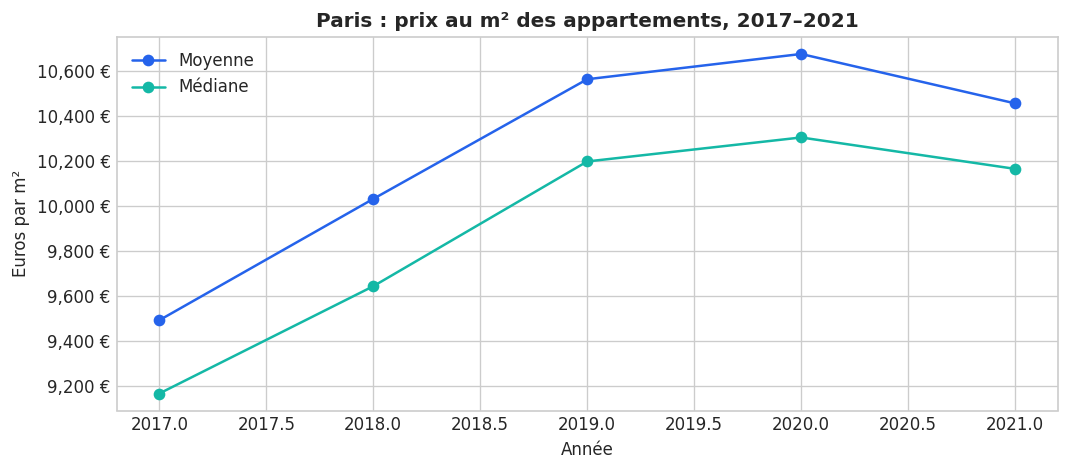

In [6]:
appartements = historique.loc[historique.type_local.eq("Appartement")].copy()
prix_annuel = appartements.groupby("annee")["prix_m2"].agg(moyenne="mean", mediane="median", transactions="size")
display(prix_annuel)
variation_17_21 = (prix_annuel.loc[2021,"moyenne"] / prix_annuel.loc[2017,"moyenne"] - 1) * 100
print(f"Variation de la moyenne 2017–2021 : {variation_17_21:.1f}%")
ax = prix_annuel[["moyenne", "mediane"]].plot(marker="o", figsize=(9,4), color=["#2563eb", "#14b8a6"])
ax.set(title="Paris : prix au m² des appartements, 2017–2021", xlabel="Année", ylabel="Euros par m²")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f} €")); ax.legend(["Moyenne", "Médiane"], frameon=False); plt.tight_layout(); plt.show()

La moyenne progresse de 2017 à 2020, puis recule légèrement en 2021. Le changement entre première et dernière année compare des moyennes de transactions et n’est pas corrigé de l’inflation ni de la composition des biens vendus.

## 6. Différences entre arrondissements

annee         2017   2018   2019   2020   2021
code_postal                                   
75001        11763  12621  13269  13406  13379
75002        10920  11309  12151  12182  11773
75003        11680  12470  12813  12834  12661
75004        12407  13432  13641  13105  12937
75005        11307  12056  12928  12960  12606
75006        12509  12896  13378  13807  13795
75007        11845  12553  12922  13110  13118
75008        10133  10631  11195  11703  11710
75009         9582  10187  10958  10981  10732
75010         8747   9328   9999  10200  10043
75011         9138   9689  10377  10533  10352
75012         8455   8938   9498   9691   9658
75013         8345   8755   9340   9334   9165
75014         9055   9434  10027  10108   9994
75015         9098   9328   9822  10061   9971
75016         9809  10244  10825  10911  10790
75017         9337   9881  10400  10536  10372
75018         8466   9153   9928   9947   9666
75019         7622   8266   8850   8983   8829
75020        

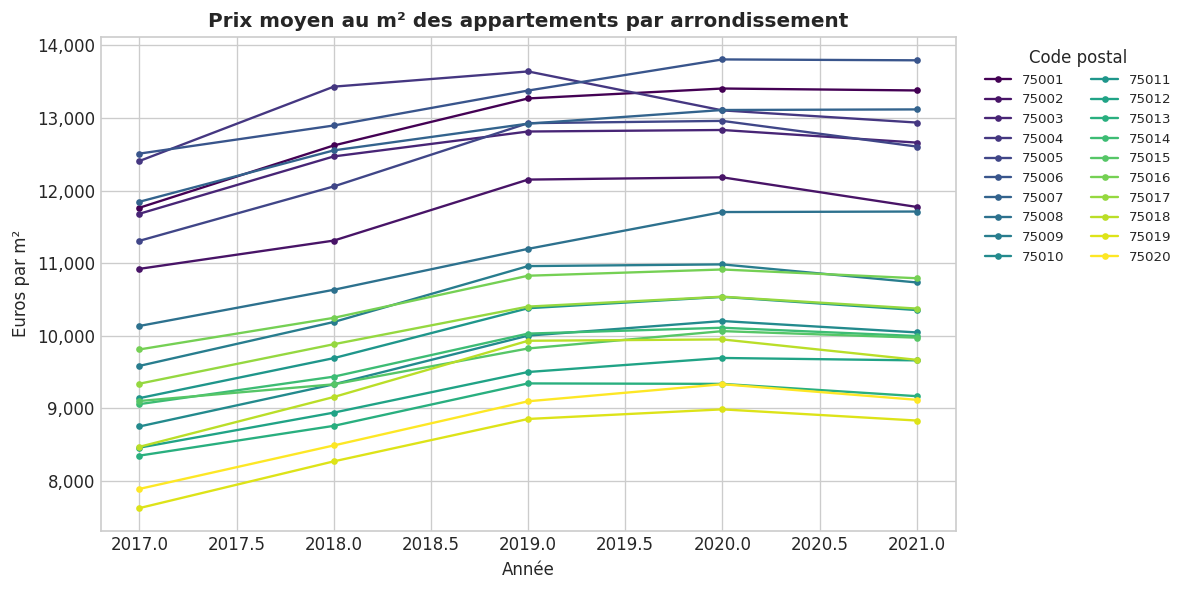

In [7]:
prix_arrondissement = appartements.pivot_table(index="code_postal", columns="annee", values="prix_m2", aggfunc="mean")
display(prix_arrondissement.round(0).astype("Int64"))
ax = prix_arrondissement.T.plot(figsize=(10,5), marker=".", linewidth=1.4, colormap="viridis")
ax.set(title="Prix moyen au m² des appartements par arrondissement", xlabel="Année", ylabel="Euros par m²")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}")); ax.legend(title="Code postal", bbox_to_anchor=(1.02,1), loc="upper left", ncol=2, fontsize=8); plt.tight_layout(); plt.show()
print("Moyenne 2021 — cinq arrondissements les plus élevés :")
display(prix_arrondissement[2021].sort_values(ascending=False).head(5).rename("€/m², 2021").to_frame())
print("Moyenne 2021 — cinq arrondissements les plus bas :")
display(prix_arrondissement[2021].sort_values().head(5).rename("€/m², 2021").to_frame())

Les moyennes par arrondissement montrent des écarts géographiques nets. Elles restent sensibles à la taille et au type des biens vendus chaque année; elles ne contrôlent pas les caractéristiques individuelles des logements.

## 7. Prix par transaction dans le 6e arrondissement

Transactions d’appartements dans le 6e : 709
       prix au m²
count      709.00
mean    13,143.51
std        565.78
min     12,065.24
25%     12,647.67
50%     13,122.73
75%     13,631.59
max     14,169.82


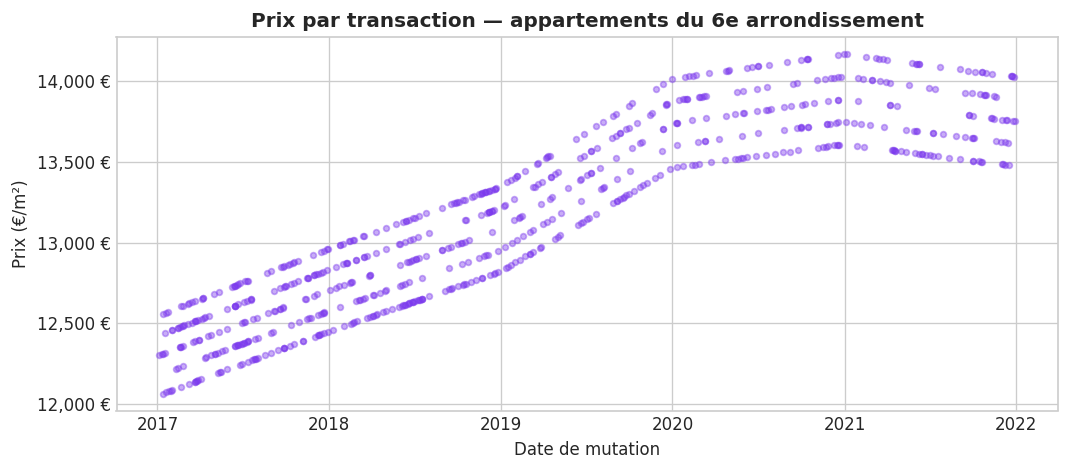

In [8]:
transactions_75006 = appartements.loc[appartements.code_postal.eq(75006)]
print("Transactions d’appartements dans le 6e :", len(transactions_75006))
display(transactions_75006["prix_m2"].describe().to_frame("prix au m²"))
plt.figure(figsize=(9,4)); plt.scatter(transactions_75006.date_mutation, transactions_75006.prix_m2, s=12, alpha=.42, color="#7c3aed")
plt.title("Prix par transaction — appartements du 6e arrondissement")
plt.xlabel("Date de mutation"); plt.ylabel("Prix (€/m²)"); plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f} €")); plt.tight_layout(); plt.show()

Le nuage de points permet de voir les dispersions transaction par transaction, les tendances temporelles et d’éventuelles valeurs extrêmes. Le 6e arrondissement est retenu comme exemple, conformément au notebook modèle.

## 8. Corrélation entre prix au m² et date

In [9]:
r_date, p_date = pearsonr(historique["prix_m2"], historique["date_annees"])
print(f"Pearson r = {r_date:.3f} ; p-value = {p_date:.3g} ; n = {len(historique):,}")

Pearson r = 0.267 ; p-value = 0 ; n = 26,196


La corrélation linéaire est positive, mais sa taille doit guider le commentaire : elle décrit une association moyenne sur l’ensemble des ventes, pas un effet causal du temps. Les changements de composition des biens et les tendances non linéaires ne sont pas contrôlés par ce coefficient.

## 9. Corrélation entre prix au m² et surface

Pearson r = 0.103 ; p-value = 7.24e-63 ; n = 26,196


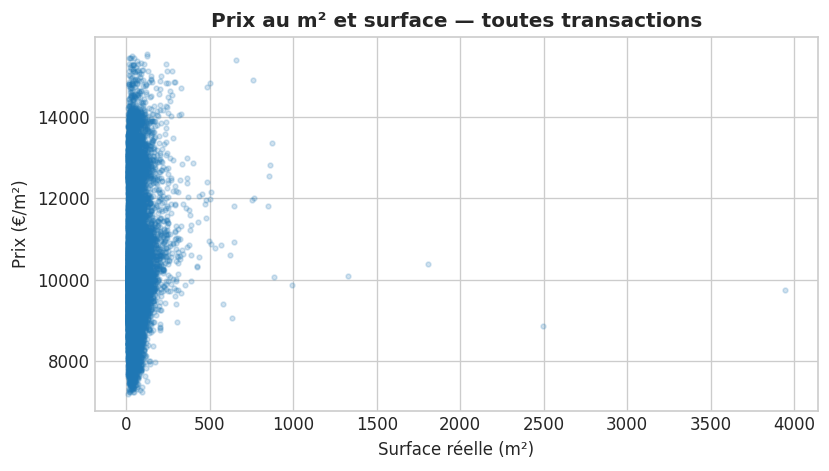

In [10]:
r_surface, p_surface = pearsonr(historique["prix_m2"], historique["surface_reelle"])
print(f"Pearson r = {r_surface:.3f} ; p-value = {p_surface:.3g} ; n = {len(historique):,}")
plt.figure(figsize=(7,4)); plt.scatter(historique.surface_reelle, historique.prix_m2, s=8, alpha=.2)
plt.title("Prix au m² et surface — toutes transactions"); plt.xlabel("Surface réelle (m²)"); plt.ylabel("Prix (€/m²)"); plt.tight_layout(); plt.show()

Une valeur p très faible est favorisée par le grand nombre de lignes; le coefficient r renseigne sur l’intensité de l’association. Le prix total et le prix au m² sont deux mesures différentes : la modélisation ci-dessous estime d’abord le prix au m² puis le multiplie par la surface.

## 10. Comparaison des types de biens

                                           moyenne   mediane  transactions
type_local                                                                
Appartement                              10,221.63  9,962.34         24353
Local industriel. commercial ou assimilé 11,705.02 11,322.01          1843
Écart de moyenne locaux vs appartements : 14.5%


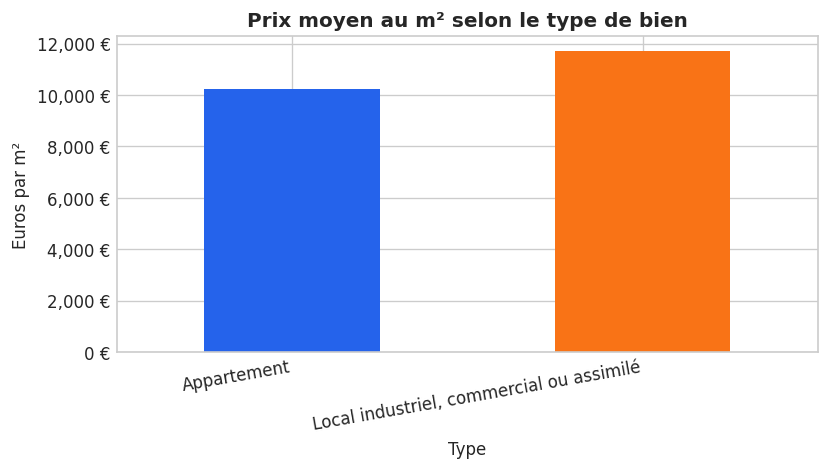

In [11]:
comparaison_types = historique.groupby("type_local")["prix_m2"].agg(moyenne="mean", mediane="median", transactions="size")
display(comparaison_types)
locaux = historique.loc[historique.type_local.ne("Appartement"), "prix_m2"].mean()
apt_moy = historique.loc[historique.type_local.eq("Appartement"), "prix_m2"].mean()
print(f"Écart de moyenne locaux vs appartements : {(locaux/apt_moy-1)*100:.1f}%")
ax = comparaison_types["moyenne"].plot.bar(figsize=(7,4), color=["#2563eb", "#f97316"])
ax.set(title="Prix moyen au m² selon le type de bien", xlabel="Type", ylabel="Euros par m²")
ax.set_xticklabels(["Appartement", "Local industriel, commercial ou assimilé"], rotation=10, ha="right")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f} €")); plt.tight_layout(); plt.show()

Dans cet historique, les locaux commerciaux et assimilés affichent une moyenne €/m² supérieure à celle des appartements. Ce constat descriptif ne tient pas compte des différences d’usage, de surface et de localisation.

## Modèle de régression linéaire : test chronologique

### Choix de la cible et des variables
La cible est le logarithme du prix au m². Les variables explicatives sont la date numérique, la surface réelle, le code postal et le type de bien; les variables catégorielles sont transformées par one-hot encoding. La prédiction du prix total s’obtient ensuite par `prix_m2_prédit × surface`. Cette formulation respecte la relation comptable entre prix au m² et valeur totale et évite de confondre l’effet d’échelle de la surface avec le niveau de prix unitaire.

Le découpage est manuel et chronologique : 2017–2020 pour l’apprentissage, 2021 pour le test. Il respecte l’ordre temporel demandé. La métrique principale est la moyenne des erreurs absolues relatives, calculée ligne par ligne, puis exprimée en pourcentage.

In [12]:
features = ["date_annees", "surface_reelle", "code_postal", "type_local"]
categoricals = ["code_postal", "type_local"]
X = pd.get_dummies(historique[features], columns=categoricals, dtype=float)
y = np.log(historique["prix_m2"])
mask_train = historique["date_mutation"] < pd.Timestamp("2021-01-01")
mask_test = ~mask_train
X_train, X_test = X.loc[mask_train], X.loc[mask_test]
y_train = y.loc[mask_train]
# Alignement explicite des colonnes encodées et séparation manuelle des cibles
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_total = historique["valeur_fonciere"]
y_test_total = y_total.loc[mask_test]
print("Apprentissage :", mask_train.sum(), "lignes jusqu’au", historique.loc[mask_train,"date_mutation"].max().date())
print("Test :", mask_test.sum(), "lignes à partir du", historique.loc[mask_test,"date_mutation"].min().date())

Apprentissage : 21128 lignes jusqu’au 2020-12-31
Test : 5068 lignes à partir du 2021-01-04


In [13]:
modele = LinearRegression()
modele.fit(X_train, y_train)
prediction_test_m2 = np.exp(modele.predict(X_test))
prediction_test_total = prediction_test_m2 * historique.loc[mask_test, "surface_reelle"].to_numpy()
valeurs_reelles_test = y_test_total.to_numpy()
ape_test = np.abs(prediction_test_total - valeurs_reelles_test) / valeurs_reelles_test
mape = ape_test.mean() * 100
mae = mean_absolute_error(valeurs_reelles_test, prediction_test_total)
rmse = mean_squared_error(valeurs_reelles_test, prediction_test_total) ** 0.5
r2 = r2_score(valeurs_reelles_test, prediction_test_total)
biais_pct = np.mean((prediction_test_total - valeurs_reelles_test) / valeurs_reelles_test) * 100
print(f"Erreur absolue relative moyenne (test 2021) : {mape:.2f}%")
print(f"MAE : {mae:,.0f} € | RMSE : {rmse:,.0f} € | R² : {r2:.4f} | biais relatif moyen : {biais_pct:+.2f}%")
print("Médiane des erreurs absolues relatives :", f"{np.median(ape_test)*100:.2f}%")

Erreur absolue relative moyenne (test 2021) : 7.87%
MAE : 40,009 € | RMSE : 64,111 € | R² : 0.9885 | biais relatif moyen : +7.86%
Médiane des erreurs absolues relatives : 7.90%


### Lecture critique du modèle
Le score de test doit être interprété avec le découpage temporel précis indiqué ci-dessus. La moyenne des erreurs relatives est sensible aux petites valeurs et aux biens atypiques; l’erreur en euros (MAE/RMSE) la complète. Les données sont historiques et le modèle extrapole ensuite au 31/12/2022. Les écarts de marché après 2021, l’état du bien, l’étage, la qualité, le DPE, la copropriété et la nature précise d’un local ne sont pas modélisés. Le score de 2021 ne garantit pas la même précision sur le portefeuille.

## Valorisation du portefeuille au 31 décembre 2022

In [14]:
portefeuille["surface_reelle"] = portefeuille["surface_reelle_bati"]
portefeuille["date_annees"] = (pd.Timestamp("2022-12-31") - pd.Timestamp("2017-01-01")).days / 365.25
X_portefeuille = pd.get_dummies(portefeuille[features], columns=categoricals, dtype=float)
X_portefeuille = X_portefeuille.reindex(columns=X_train.columns, fill_value=0)
portefeuille["prix_m2_estime"] = np.exp(modele.predict(X_portefeuille))
portefeuille["valeur_estimee_2022_12_31"] = portefeuille["prix_m2_estime"] * portefeuille["surface_reelle"]
portefeuille.insert(0, "id_bien", np.arange(1, len(portefeuille)+1))
resume_portefeuille = portefeuille.groupby("type_local").agg(nombre_de_biens=("id_bien","count"),surface_totale_m2=("surface_reelle","sum"),valeur_estimee_euros=("valeur_estimee_2022_12_31","sum"))
display(resume_portefeuille)
print(f"Valorisation totale estimée : {portefeuille.valeur_estimee_2022_12_31.sum():,.0f} €")

                                          nombre_de_biens  surface_totale_m2  valeur_estimee_euros
type_local                                                                                        
Appartement                                           154               6286         74,566,946.80
Local industriel. commercial ou assimilé              121               7696        105,791,140.86
Valorisation totale estimée : 180,358,088 €


Le fichier du portefeuille ne contient pas de variable de branche ou de segment commercial. Le tableau ventile donc la valorisation selon le type de bien (appartement / local industriel, commercial ou assimilé), qui ne doit pas être présenté comme un découpage organisationnel de l’entreprise.

Le modèle utilise `surface_reelle_bati` comme surface réelle, conformément à la note du modèle de code. La colonne `surface_carrez` n’est pas substituée.

In [15]:
sortie_csv = OUT_DIR / "predictions_valorisation_portefeuille_2022-12-31.csv"
colonnes_export = ["id_bien", "adresse_numero", "adresse_nom_voie", "code_postal", "nom_commune", "type_local", "surface_reelle_bati", "prix_m2_estime", "valeur_estimee_2022_12_31"]
portefeuille[colonnes_export].to_csv(sortie_csv, index=False, encoding="utf-8-sig", float_format="%.2f")
print("CSV exporté :", sortie_csv, "—", len(portefeuille), "biens")
portefeuille[colonnes_export].head()

CSV exporté : livrables/predictions_valorisation_portefeuille_2022-12-31.csv — 275 biens


## Classification non supervisée avec K-means

Pour simuler le tri d’opportunités, K-means est entraîné sans la colonne du type de bien et uniquement sur le prix au m² des transactions 2017–2020. Les étiquettes connues de cette période servent après entraînement à donner un nom interprétable aux groupes (le groupe où les locaux sont proportionnellement les plus représentés devient le groupe « local »). La mesure de performance se fait ensuite sur 2021, qui n’a servi ni à ajuster les centres ni à définir leur nom. Ce test historique ne remplace pas la comparaison au fichier de test et aux étiquettes de Louise.

In [16]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=20)
kmeans.fit(historique.loc[mask_train, ["prix_m2"]])
clusters_train = pd.Series(kmeans.labels_, index=historique.index[mask_train], name="cluster")
taux_locaux = pd.crosstab(clusters_train, historique.loc[mask_train, "type_local"], normalize="index")
display(taux_locaux)
classe_local = taux_locaux["Local industriel. commercial ou assimilé"].idxmax()
print("Centres des groupes (€/m²) :", np.round(kmeans.cluster_centers_.ravel(), 0))
print("Groupe interprété comme ‘local commercial’, selon les étiquettes d’apprentissage :", classe_local)

type_local  Appartement  Local industriel. commercial ou assimilé
cluster                                                          
0                  0.96                                      0.04
1                  0.83                                      0.17
Centres des groupes (€/m²) : [ 9583. 12426.]
Groupe interprété comme ‘local commercial’, selon les étiquettes d’apprentissage : 1


In [17]:
clusters_test = kmeans.predict(historique.loc[mask_test, ["prix_m2"]])
classe_predite = np.where(clusters_test == classe_local, "Local industriel. commercial ou assimilé", "Appartement")
classe_reelle = historique.loc[mask_test, "type_local"].to_numpy()
matrice = pd.crosstab(pd.Series(classe_reelle, name="Type réel 2021"), pd.Series(classe_predite, name="Type prédit"))
display(matrice)
precision_local = precision_score(classe_reelle, classe_predite, pos_label="Local industriel. commercial ou assimilé", zero_division=0)
rappel_local = recall_score(classe_reelle, classe_predite, pos_label="Local industriel. commercial ou assimilé", zero_division=0)
f1_local = f1_score(classe_reelle, classe_predite, pos_label="Local industriel. commercial ou assimilé", zero_division=0)
exactitude = accuracy_score(classe_reelle, classe_predite)
exactitude_equilibree = balanced_accuracy_score(classe_reelle, classe_predite)
score_silhouette = silhouette_score(historique.loc[mask_test, ["prix_m2"]], clusters_test)
reference_majoritaire = pd.Series(classe_reelle).value_counts(normalize=True).max()
print(f"Exactitude globale : {exactitude:.1%}; équilibrée : {exactitude_equilibree:.1%}")
print(f"Locaux — précision : {precision_local:.1%}; rappel : {rappel_local:.1%}; F1 : {f1_local:.1%}")
print(f"Silhouette : {score_silhouette:.3f}; référence ‘tout appartement’ : {reference_majoritaire:.1%}")

Type prédit                               Appartement  Local industriel. commercial ou assimilé
Type réel 2021                                                                                 
Appartement                                      3782                                       911
Local industriel. commercial ou assimilé           99                                       276
Exactitude globale : 80.1%; équilibrée : 77.1%
Locaux — précision : 23.3%; rappel : 73.6%; F1 : 35.3%
Silhouette : 0.693; référence ‘tout appartement’ : 92.6%


Le score global peut masquer le déséquilibre entre types. La précision du groupe « locaux » mesure les biens signalés comme locaux qui le sont effectivement; le rappel mesure les locaux retrouvés. Le score silhouette mesure la séparation des groupes sur le prix au m², pas la justesse des types. Si la précision est faible, une classification automatique risquerait de multiplier les fausses alertes. La comparaison officielle sur l’échantillon de Louise reste à faire avec les étiquettes réelles fournies par son équipe.

In [18]:
def classer_opportunites(df, colonne_prix, colonne_surface):
    # Les colonnes doivent être numériques; la sortie est une aide au tri, pas une décision automatique.
    prix_m2 = pd.to_numeric(df[colonne_prix], errors="coerce") / pd.to_numeric(df[colonne_surface], errors="coerce")
    if prix_m2.isna().any() or (prix_m2 <= 0).any():
        raise ValueError("Chaque opportunité doit avoir un prix et une surface strictement positifs.")
    resultat = df.copy()
    groupes = kmeans.predict(prix_m2.to_frame(name="prix_m2"))
    resultat["cluster_kmeans"] = groupes
    resultat["nature_estimee"] = np.where(groupes == classe_local, "Local industriel, commercial ou assimilé", "Appartement")
    return resultat

# À lancer lorsque l’échantillon de Louise est disponible :
# echantillon = pd.read_excel(DATA_DIR / "echantillon_a_classer2.xlsx")
# echantillon_classe = classer_opportunites(echantillon, colonne_prix="<colonne prix>", colonne_surface="<colonne surface>")

## Conclusions à présenter au client
1. Dans le fichier fourni, les prix moyens €/m² des appartements montent entre 2017 et 2020 puis reculent un peu en 2021.
2. Les prix varient selon l’arrondissement; les moyennes ne corrigent pas la composition des ventes.
3. Le modèle chronologique atteint le niveau d’erreur observé dans le bloc de métriques sur le test 2021, sans que cela constitue une garantie pour 2022.
4. La valeur agrégée et la ventilation par type sont estimées; elles doivent être confirmées avec l’entreprise et confrontées à des évaluations indépendantes.

### À valider avant la soutenance
- Confirmer que la cible, la date de valorisation et le périmètre des transactions correspondent bien au brief de votre espace OC.
- Confirmer l’interprétation des 16 lignes strictement identiques.
- Confirmer si l’entreprise attend une ventilation par branche; le fichier ne fournit actuellement que le type de bien.
- Expliquer que l’algorithme ne remplace pas une expertise immobilière.